# 02 - Statistics

Correlation, the OLS regression with VIF and Moran's I, and the built-up versus green comparison.

In [1]:
import sys
from pathlib import Path

# notebooks live one level below the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import load_config
from src.data import db as db_mod

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
%matplotlib inline


In [2]:
cfg = load_config(ROOT / 'config.yaml')
engine = db_mod.get_engine(cfg)

## Correlation (Pearson and Spearman)

In [3]:
db_mod.read_table(engine, 'correlation_results').round(4)

,variable,pearson_r,pearson_p,spearman_rho,spearman_p,n
0,ndvi_mean,-0.7750,0.0000,-0.8078,0.0000,192
1,builtup_frac,0.8940,0.0000,0.8840,0.0000,192
2,dist_water_m,-0.2435,0.0007,-0.2756,0.0001,192


## OLS regression with VIF

In [4]:
db_mod.read_table(engine, 'regression_results').round(4)

,term,coef,std_err,p_value,ci_low,ci_high,vif
0,const,25.1718,0.3136,0.0,24.5532,25.7905,NaN
1,ndvi_mean,-3.0821,0.3894,0.0,-3.8503,-2.3139,2.6014
2,builtup_frac,8.2133,0.3363,0.0,7.5499,8.8767,2.7509
3,dist_water_m,0.0016,0.0001,0.0,0.0014,0.0018,1.4508


In [5]:
summary = db_mod.read_table(engine, 'model_summary').set_index('metric')['value']
summary.round(4)

metric
n_obs                 192.0000
r2                      0.9112
adj_r2                  0.9098
f_stat                642.9096
f_pvalue                0.0000
aic                   490.8679
rmse                    0.8509
moran_i_residuals       0.3098
max_vif                 2.7509
ndvi_coef              -3.0821
cooling_estimate_c      0.3082
ndvi_uplift             0.1000
Name: value, dtype: float64

### Residual diagnostics

In [6]:
samples = db_mod.read_table(engine, 'samples')
feats = db_mod.read_table(engine, 'sample_features')
df = samples.merge(feats, on='sample_id')
df = df[df['is_outlier'] == 0]
df = df.dropna(subset=['temp_c', 'ndvi_mean', 'builtup_frac', 'dist_water_m'])

from src.analysis import stats as st
coef, summ, model, fitted, std = st.regress(df)
fitted.head()

,temp_c,ndvi_mean,builtup_frac,dist_water_m,fitted,residual
0,33.692474,-0.120790,0.677033,27.163483,31.147872,2.544602
1,30.053429,0.280323,0.709857,346.550935,30.687400,-0.633970
2,32.615994,0.117987,0.800959,367.999658,31.969984,0.646010
3,29.131805,0.150841,0.612749,46.146156,29.812774,-0.680970
4,28.368492,0.446105,0.515224,169.983820,28.298013,0.070479


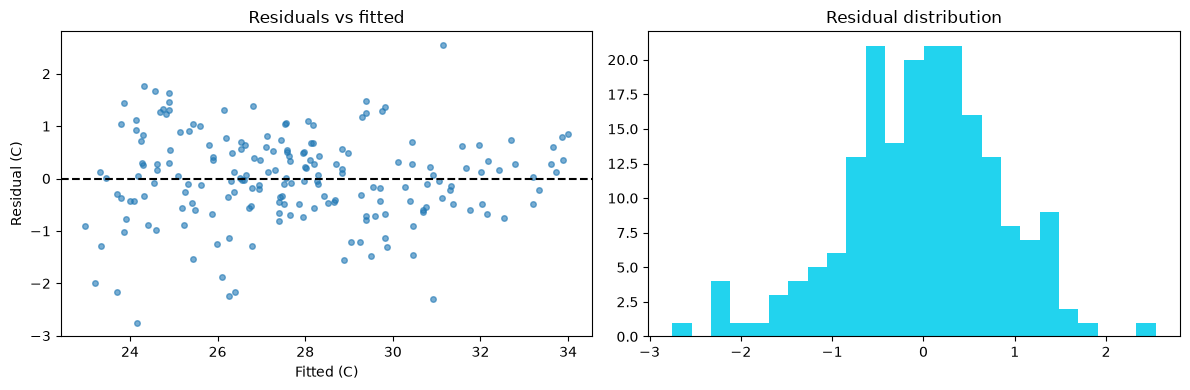

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fitted['fitted'], fitted['residual'], s=16, alpha=0.6)
axes[0].axhline(0, color='k', ls='--')
axes[0].set_xlabel('Fitted (C)'); axes[0].set_ylabel('Residual (C)')
axes[0].set_title('Residuals vs fitted')
axes[1].hist(fitted['residual'].dropna(), bins=25, color='#22d3ee')
axes[1].set_title('Residual distribution')
plt.tight_layout(); plt.show()

## Built-up versus green

In [8]:
db_mod.read_table(engine, 'group_comparison').round(5)

,group_a,group_b,mean_a,mean_b,diff,welch_p,mannwhitney_p,cohens_d
0,built_up,green,30.97979,26.59305,4.38674,0.0,0.0,2.11775


**Read this.** A positive Moran's I on the residuals means nearby samples are more alike than chance, so the OLS p-values are optimistic. The effect sizes are still large and consistent.